In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## load subreddit sets

In [2]:
sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")

subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}

matched1_indp = subreddit_sets["matched1_indp"]
matched2_indp= subreddit_sets["matched2_indp"]
matched2_conn = subreddit_sets["matched2_conn"]
random = subreddit_sets["random"]
banned = subreddit_sets["banned"]

In [ ]:
from src.utils.graph_tool_functions import read_network_gt, remove_user_page_nodes
import graph_tool.all as gt 
from graph_tool.all import load_graph

def get_kcore_df(g):
    kcore = gt.kcore_decomposition(g)
    df_kcore = pl.DataFrame({
        "node_id": [int(v) for v in g.vertices()],
        "name": [g.vp["name"][v].lower().strip() for v in g.vertices()],
        "kcore": [int(kcore[v]) for v in g.vertices()],
    })
    return df_kcore

def get_strength_df(g):
    weight = g.ep["weight"]
    df_strength = pl.DataFrame({
        "node_id": [int(v) for v in g.vertices()],
        "name": [g.vp["name"][v].lower().strip() for v in g.vertices()],
        "strength": [float(v.out_degree(weight=weight)) for v in g.vertices()],
    })

    return df_strength

def get_eigenvector_df(g):
    weight = g.ep["weight"]
    eigval, eigvec = gt.eigenvector(g, weight=weight, epsilon=1e-6, max_iter=1000)

    df_eigen = pl.DataFrame({
        "node_id": [int(v) for v in g.vertices()],
        "name": [g.vp["name"][v].lower().strip() for v in g.vertices()],
        "eigenvector": [float(eigvec[v]) for v in g.vertices()],
    })

    return df_eigen

def get_pagerank_df(g):
    weight = g.ep["weight"]

    pr = gt.pagerank(g, weight=weight, epsilon=1e-6, max_iter=1000)

    df_pr = pl.DataFrame({
        "node_id": [int(v) for v in g.vertices()],
        "name": [g.vp["name"][v].lower().strip() for v in g.vertices()],
        "pagerank": [float(pr[v]) for v in g.vertices()],
    })

    return df_pr

# input_fpath = "/cinddata/Reddit_processed/comments/networks/full"
input_fpath = "/cinddata/Reddit_processed/comments_submissions/networks/full"
years = range(2006, 2020)
kcore_dfs = {}
strength_dfs = {}
eigenvec_dfs = {}
pr_dfs = {}
for y in years:
    # print(f"processing for year {y}:")
    # print("\tloading graph...")
    # g = load_graph(f"{input_fpath}/{y}.gt.gz")

    # Lluis' network filters out u_ pages anyways
    # print(f"\tOriginal network: {g.num_vertices():,} nodes, {g.num_edges():,} edges")
    # g_filtered = remove_user_page_nodes(g)
    # print(f"\tFiltered network: {g_filtered.num_vertices():,} nodes, {g_filtered.num_edges():,} edges")

    # print("\tcomputing kcore...")
    # df_kcore = get_kcore_df(g)
    # df_kcore.write_parquet(f"{DATAPATH}/output/network-desc/kcore/upage_filtered_submission_comment_network_full_{y}.parquet", compression="snappy")
    # print("\tkcore output saved!")

    # print("\tcomputing strength...")
    # df_strength = get_strength_df(g)
    # df_strength.write_parquet(f"{DATAPATH}/output/network-desc/strength/upage_filtered_submission_comment_network_full_{y}.parquet", compression="snappy")
    # print("\tstrength output saved!")

    # print("\tcomputing weighted eigenvector centrality...")
    # df_eigen = get_eigenvector_df(g)
    # df_eigen.write_parquet(f"{DATAPATH}/output/network-desc/eigenvec-centrality/upage_filtered_submission_comment_network_full_{y}.parquet", compression="snappy")
    # print("\tweighted eigenvector centrality output saved!")

    # print("\tcomputing pagerank...")
    # df_pr = get_pagerank_df(g)
    # df_pr.write_parquet(f"{DATAPATH}/output/network-desc/pagerank/upage_filtered_submission_comment_network_full_{y}.parquet", compression="snappy")
    # print("\tpagerank output saved!")
    
    kcore_df = pl.read_parquet(f"{DATAPATH}/output/network-desc/kcore/upage_filtered_submission_comment_network_full_{y}.parquet")
    kcore_df = kcore_df.filter(~pl.col("name").str.starts_with("u_"))
    kcore_dfs[y] = kcore_df
    strength_df = pl.read_parquet(f"{DATAPATH}/output/network-desc/strength/upage_filtered_submission_comment_network_full_{y}.parquet")
    strength_df = strength_df.filter(~pl.col("name").str.starts_with("u_"))
    strength_dfs[y] = strength_df
    eigenvec_df = pl.read_parquet(f"{DATAPATH}/output/network-desc/eigenvec-centrality/upage_filtered_submission_comment_network_full_{y}.parquet")
    eigenvec_df = eigenvec_df.filter(~pl.col("name").str.starts_with("u_"))
    eigenvec_dfs[y] = eigenvec_df
    pr_df = pl.read_parquet(f"{DATAPATH}/output/network-desc/pagerank/upage_filtered_submission_comment_network_full_{y}.parquet")
    pr_df = pr_df.filter(~pl.col("name").str.starts_with("u_"))
    pr_dfs[y] = pr_df

/home/yijingch@kite.upenn.edu/.conda/envs/reddit-ban-2020/lib/python3.9/site-packages/graph_tool/draw/cairo_draw.py:1553: RuntimeWarning: Error importing Gtk module: ; GTK+ drawing will not work.
  warnings.warn(msg, RuntimeWarning)


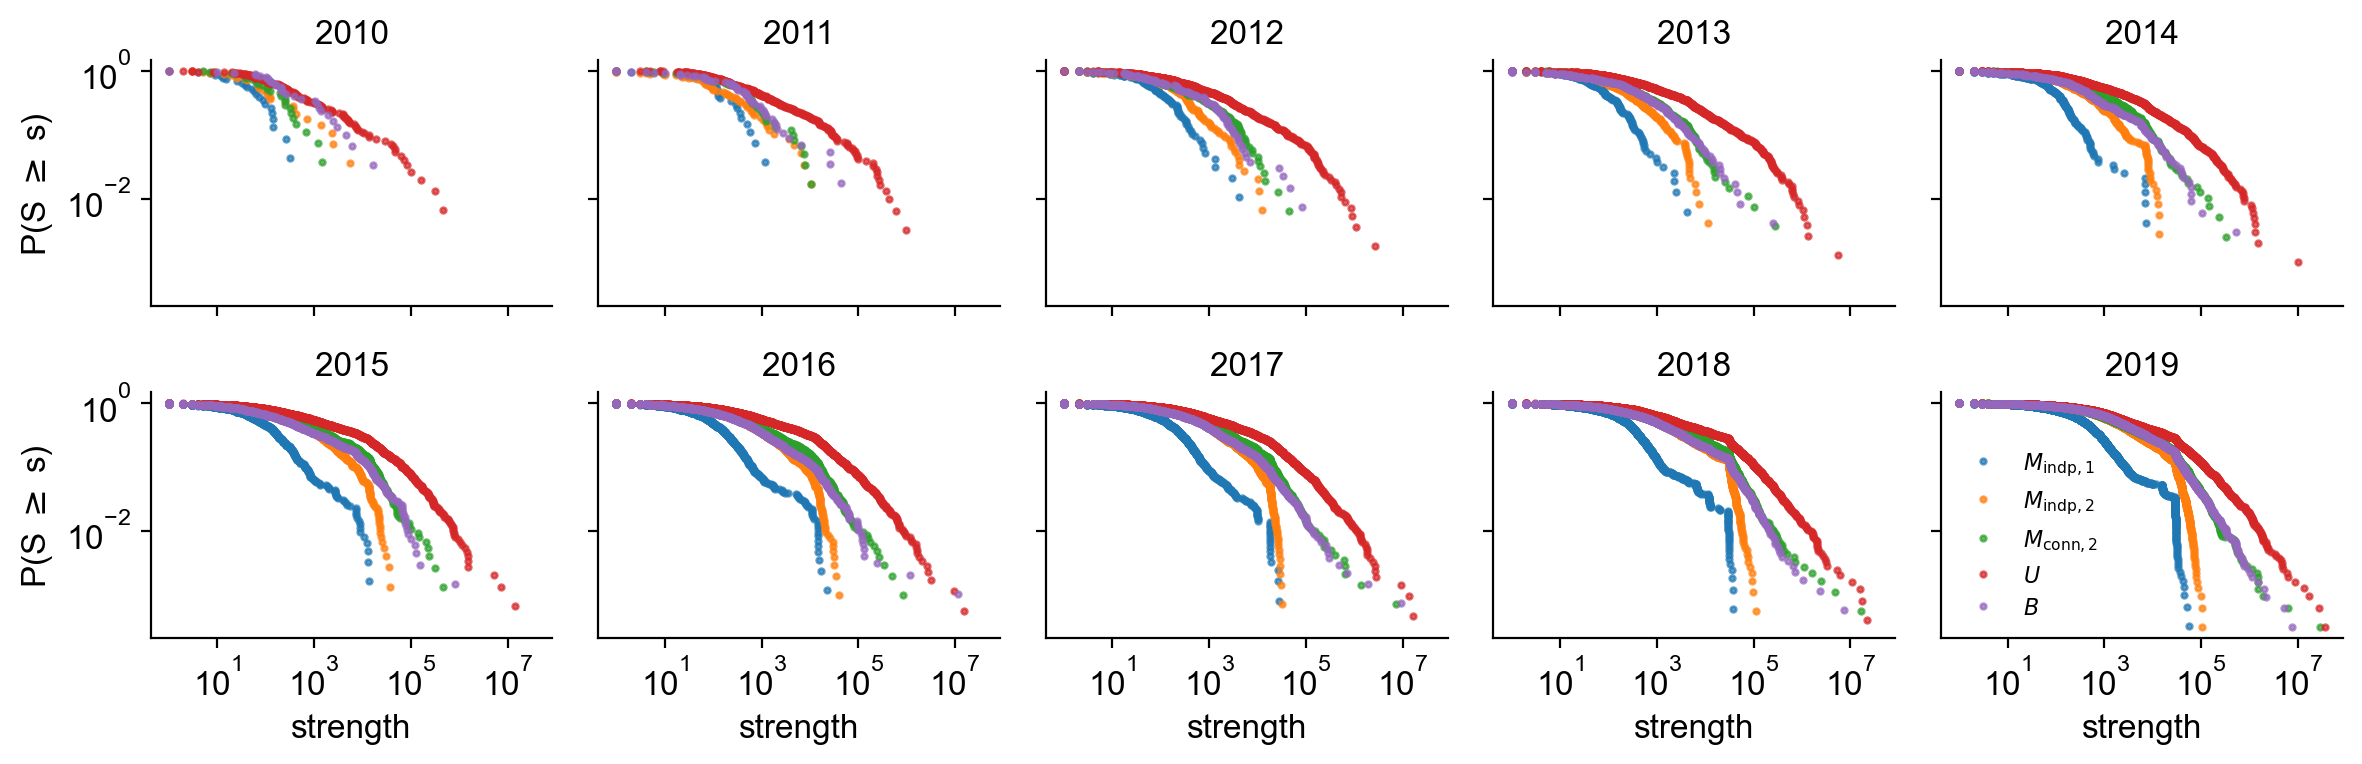

In [4]:
groups = {
    "matched1_indp": matched1_indp,
    "matched2_indp": matched2_indp,
    "matched2_conn": matched2_conn,
    "random": random,
    "banned": banned,
}

group_names = [r"$M_{\mathrm{indp},1}$", r"$M_{\mathrm{indp},2}$", r"$M_{\mathrm{conn},2}$", r"$U$", r"$B$"]
colors = dict(zip(groups, plt.cm.tab10.colors))

def plot_metric_ccdf(metric_dfs, metric, year, ax):
    df = metric_dfs[year]
    for i, (label, subs) in enumerate(groups.items()):
        vals = (
            df.filter(pl.col("name").is_in(subs))
              .get_column(metric)
              .to_numpy()
        )
        vals = vals[vals > 0]                      # log scale can't show zeros
        if vals.size == 0:
            continue
        x = np.sort(vals)
        ccdf = 1.0 - np.arange(x.size) / x.size   # P(S >= x)
        ax.loglog(
            x, 
            ccdf, ".", 
            ms=4, alpha=0.7,
            color=colors[label], 
            # label=f"{label} (n={x.size})",
            label=group_names[i]
            )
    ax.set_title(year, fontsize=12)
    # ax.set_xlabel(metric)
    # ax.set_ylabel(r"P(S $\geq$ s)")

# one panel per year
metric = "strength"
years = range(2010, 2020)
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(12, 4),sharey=True, squeeze=False, sharex=True)
axes = [x for ls in axes for x in ls]
for ax, year in zip(axes, years):
    plot_metric_ccdf(strength_dfs, metric, year, ax)
    if year >=2015: 
        ax.set_xlabel(metric, fontsize=12)
    if year in [2010, 2015]:
        ax.set_ylabel(r"P(S $\geq$ s)")
axes[-1].legend(fontsize=8)
fig.tight_layout()
# plt.savefig(f"../../output/appendix/loglog_{metric}_2010_2019_5groups.png", dpi=300, bbox_inches="tight")
# plt.savefig(f"../../output/appendix/loglog_{metric}_2010_2019_5groups.pdf", dpi=300, bbox_inches="tight")

In [5]:
groups = {
    "matched1_indp": matched1_indp,
    "matched2_indp": matched2_indp,
    "matched2_conn": matched2_conn,
    "random": random,
    "banned": banned,
}

group_order = ["matched1_indp", "matched2_indp", "matched2_conn", "random", "banned"]

# group_names = ["BANNED", "MATCH-INDP-1COV", "MATCH-INDP-2COV", "MATCH-CONN-2COV", "RANDOM",]
group_names = [r"$M_{\mathrm{indp},1}$", r"$M_{\mathrm{indp},2}$", r"$M_{\mathrm{conn},2}$", r"$U$", r"$B$"]

styles = {
    "banned": dict(color="darkred", linestyle="-"),
    "matched1_indp": dict(color="steelblue", linestyle="--"),
    "matched2_indp": dict(color="darkgreen", linestyle="--"),
    "matched2_conn": dict(color="darkorange", linestyle="-."),
    "random": dict(color="grey", linestyle=":"),
}

metrics = {
    "strength":  (strength_dfs[year],  "strength",  r"$\log_{10}(\mathrm{strength}+1)$"),
    "k-core":    (kcore_dfs[year],     "kcore",     r"$\log_{10}(k+1)$"),
    "eigenvec":  (eigenvec_dfs[year],  "eigenvector",  r"$\log_{10}(x+\epsilon)$"),
    "PageRank":  (pr_dfs[year],        "pagerank",  r"$\log_{10}(x+\epsilon)$"),
}

In [6]:
def clean_names(xs):
    return [str(x).lower().strip() for x in xs]

def get_vals(df, metric_col, grp, log1p=True):
    names = clean_names(grp)

    vals = (
        df
        .with_columns(pl.col("name").str.to_lowercase().str.strip_chars())
        .filter(pl.col("name").is_in(names))
        .select(pl.col(metric_col).cast(pl.Float64))
        .drop_nulls()
        .to_series()
        .to_numpy()
    )

    vals = vals[np.isfinite(vals)]

    if log1p:
        return np.log10(vals + 1)

    positive = vals[vals > 0]
    eps = positive.min() / 10 if len(positive) > 0 else 1e-12
    return np.log10(vals + eps)

In [7]:
def get_raw_vals(df, metric_col, grp):
    names = clean_names(grp)
    vals = (
        df
        .with_columns(pl.col("name").str.to_lowercase().str.strip_chars())
        .filter(pl.col("name").is_in(names))
        .select(pl.col(metric_col).cast(pl.Float64))
        .drop_nulls()
        .to_series()
        .to_numpy()
    )
    vals = vals[np.isfinite(vals)]
    return vals[vals > 0]   # log-log plot needs positive values


def ccdf(vals):
    x = np.sort(vals)
    y = np.arange(len(x), 0, -1) / len(x)
    return x, y

In [8]:
year = 2019
metrics2 = {
    "strength":  (strength_dfs[year],  "strength",  r"$\log_{10}(\mathrm{strength}+1)$"),
    "PageRank":  (pr_dfs[year],        "pagerank",  r"$\log_{10}(x+\epsilon)$"),
}

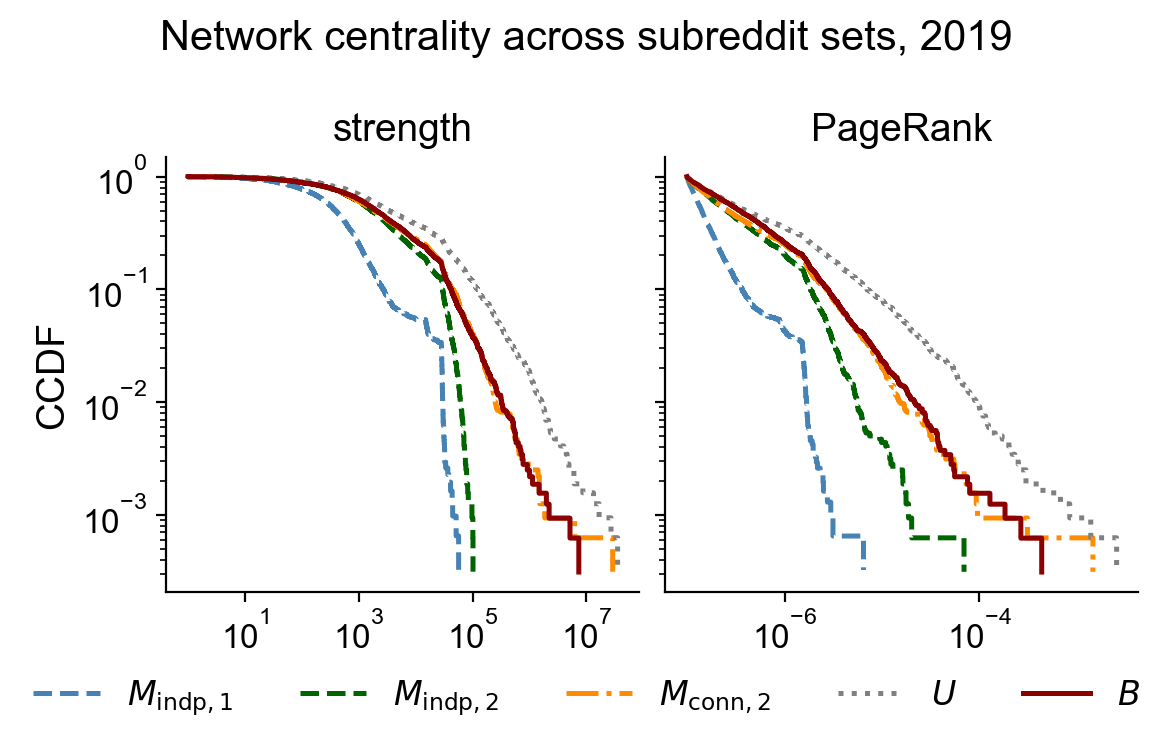

In [15]:
fig, axes = plt.subplots(
    ncols=2,
    figsize=(5.6,2.8),
    sharey=True,
    constrained_layout=True,
)

for ax, (title, (df, col, _)) in zip(axes, metrics2.items()):

    for g, label in zip(group_order, group_names):
        vals = get_raw_vals(df, col, groups[g])

        if len(vals) == 0:
            continue

        x, y = ccdf(vals)

        ax.step(
            x, y,
            where="post",
            linewidth=1.8,
            label=label,
            **styles[g],
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(title, fontsize=14)
    # ax.set_xlabel(title, fontsize=14)
    # ax.grid(alpha=0.25, which="both")

axes[0].set_ylabel("CCDF", fontsize=14)

handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=len(group_order),
    frameon=False,
    bbox_to_anchor=(0.5, -0.15),
    prop={"family": "monospace", "size": 12},
)
# plt.tight_layout()
fig.suptitle("Network centrality across subreddit sets, 2019", fontsize=15, y=1.15)
plt.savefig("../../output/mainbody/loglog_strength_pagerank_2019_5groups.png", dpi=300, bbox_inches="tight")
plt.savefig("../../output/mainbody/loglog_strength_pagerank_2019_5groups.pdf", dpi=300, bbox_inches="tight")
